Train images: (800, 1, 16, 16)
Test images:  (400, 1, 16, 16)
MLP | parameters=4146 | train acc=1.000 | shifted test acc=0.502
CNN | parameters=  98 | train acc=1.000 | shifted test acc=1.000

[CNN tensor shapes]
Input:         (8, 1, 16, 16)
Feature maps:  (8, 8, 16, 16)
Pooled:        (8, 8, 1, 1)
Flattened:     (8, 8)
Scores:        (8, 2)


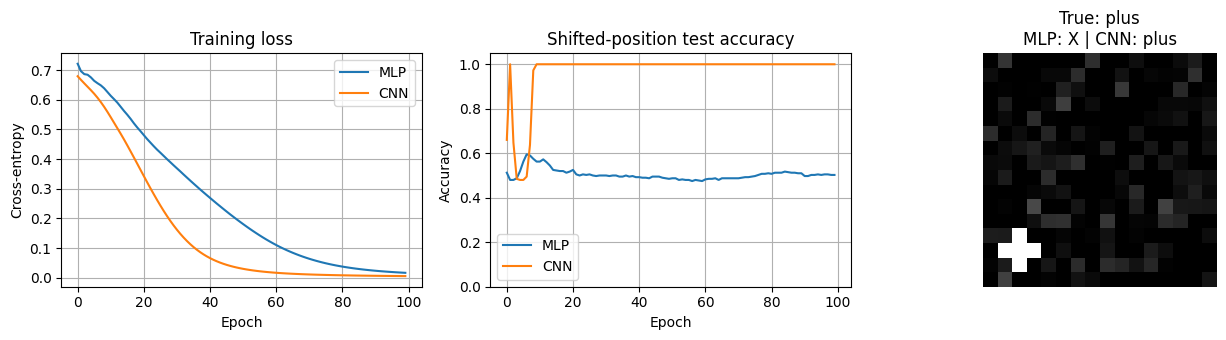

In [2]:
### CS231n_Lec05_Image_Classification_with_CNNs

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(5)
torch.set_num_threads(1)

IMAGE_SIZE = 16
NUM_CLASSES = 2
CLASS_NAMES = ("plus", "X")
EPOCHS = 100


# --------------------------------------------------
# 1. Generation of Shape Image Data
# --------------------------------------------------
def make_dataset(num_samples, center_positions, seed):
    """
    label 0: + shape
    label 1: X shape

    Place the centers of the shapes only at the positions
    included in center_positions.
    """

    # Fix seed for torch.randint
    generator = torch.Generator().manual_seed(seed)

    # Generate image space full of zero with IMAGE_SIZE×IMAGE_SIZE
    images = torch.zeros(
        num_samples, 1, IMAGE_SIZE, IMAGE_SIZE
    )

    # label → 0 or 1
    labels = torch.randint(
        0,
        NUM_CLASSES,
        (num_samples,),
        generator=generator,
    )

    positions = torch.tensor(center_positions)

    # combination of plus_offsets draws + shape
    plus_offsets = (
        (0, 0),
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    )

    # combination of x_offsets draws X shape
    x_offsets = (
        (0, 0),
        (-1, -1),
        (-1, 1),
        (1, -1),
        (1, 1),
    )

    for i in range(num_samples):
        # Select a random row and column within the range from 0 to the center.
        row_index = torch.randint(
            0, len(positions), (), generator=generator
        ).item()

        column_index = torch.randint(
            0, len(positions), (), generator=generator
        ).item()

        # Areas in the selected row and column
        center_row = positions[row_index].item()
        center_column = positions[column_index].item()

        ## label 0: +, lable 1: X
        if labels[i].item() == 0:
            offsets = plus_offsets
        else:
            offsets = x_offsets

        for row_offset, column_offset in offsets:
            row = center_row + row_offset
            column = center_column + column_offset
            images[i, 0, row, column] = 1.0

    # Add small sensor noise
    noise = 0.10 * torch.randn(
        images.shape,
        generator=generator,
    )

    images = (images + noise).clamp(0.0, 1.0)

    return images, labels


# Training: Place shapes only near the center
train_images, train_labels = make_dataset(
    num_samples=800,
    center_positions=range(5, 11),
    seed=1,
)

# Test: Edge locations not used during training
test_images, test_labels = make_dataset(
    num_samples=400,
    center_positions=(2, 3, 12, 13),
    seed=2,
)

print("Train images:", tuple(train_images.shape))
print("Test images: ", tuple(test_images.shape))


# --------------------------------------------------
# 2. Definition of Comparison Models
# --------------------------------------------------

# MLP with just Linear Classifiers
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # Input → Flatten → Linear Layer 1 → ReLU → Linear Layer 2 →Output
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(IMAGE_SIZE * IMAGE_SIZE, 16),
            nn.ReLU(),
            nn.Linear(16, NUM_CLASSES),
        )

    def forward(self, x):
        return self.network(x)


# CNN with a Convolution Layer
class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        """
        Height and width remain the same as the input
        for setting kernel_size and padding
        """

        # In (N, 1, H, W) → Out (N, 8, H, W)
        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=8,
                kernel_size=3,
                padding=1,
            ),
            nn.ReLU(),
        )

        # Pooling: Retain only the single largest value from each feature map.
        self.pool = nn.AdaptiveMaxPool2d((1, 1))

        self.classifier = nn.Linear(
            in_features=8,
            out_features=NUM_CLASSES,
        )

    def forward(self, x):
        feature_maps = self.features(x)
        pooled = self.pool(feature_maps)
        pooled = pooled.flatten(start_dim=1)
        scores = self.classifier(pooled)
        return scores


# --------------------------------------------------
# 3. Training Function
# --------------------------------------------------
def train_model(model, learning_rate=0.01):

    # Use optimizer Adam
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    # Set up the loss function and create lists for performance tracking
    criterion = nn.CrossEntropyLoss()
    loss_history = []
    train_accuracy_history = []
    test_accuracy_history = []

    for epoch in range(EPOCHS):
        # select train mode
        model.train()

        """
        Natural flow: Prediction → Loss measurement
        → Gradient initialization → Backpropagation → Optimization
        """
        scores = model(train_images)
        loss = criterion(scores, train_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # select evaluation mode
        model.eval()

        """
        After extracting training and test predictions,
        accuracy is calculated by comparing them with the actual labels.
        """
        with torch.no_grad():
            train_predictions = model(
                train_images
            ).argmax(dim=1)

            test_predictions = model(
                test_images
            ).argmax(dim=1)

            train_accuracy = (
                train_predictions == train_labels
            ).float().mean().item()

            test_accuracy = (
                test_predictions == test_labels
            ).float().mean().item()

        loss_history.append(loss.item())
        train_accuracy_history.append(train_accuracy)
        test_accuracy_history.append(test_accuracy)

    return {
        "model": model,
        "loss": loss_history,
        "train_accuracy": train_accuracy_history,
        "test_accuracy": test_accuracy_history,
    }


# Set the initialization of both models to be reproducible
torch.manual_seed(10)
mlp_result = train_model(MLPClassifier())

torch.manual_seed(10)
cnn_result = train_model(CNNClassifier())


# --------------------------------------------------
# 4. Final Result and Number of Parameters
# --------------------------------------------------
def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


for name, result in (
    ("MLP", mlp_result),
    ("CNN", cnn_result),
):

    # show the final amounts of parameters, train accuracy, and test accuracy
    print(
        f"{name:3s} | "
        f"parameters={count_parameters(result['model']):4d} | "
        f"train acc={result['train_accuracy'][-1]:.3f} | "
        f"shifted test acc={result['test_accuracy'][-1]:.3f}"
    )


# --------------------------------------------------
# 5. Check tensor shapes within the CNN
# --------------------------------------------------
cnn = cnn_result["model"]
example_batch = test_images[:8]

with torch.no_grad():
    feature_maps = cnn.features(example_batch)
    pooled = cnn.pool(feature_maps)
    flattened = pooled.flatten(start_dim=1)
    scores = cnn.classifier(flattened)

print("\n[CNN tensor shapes]")
print("Input:        ", tuple(example_batch.shape))
print("Feature maps: ", tuple(feature_maps.shape))
print("Pooled:       ", tuple(pooled.shape))
print("Flattened:    ", tuple(flattened.shape))
print("Scores:       ", tuple(scores.shape))

assert feature_maps.shape == (8, 8, 16, 16)
assert pooled.shape == (8, 8, 1, 1)
assert scores.shape == (8, 2)


# ----------------------------------------------------------
# 6. Visualization of the Learning Process and Test Images
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].plot(
    mlp_result["loss"],
    label="MLP",
)
axes[0].plot(
    cnn_result["loss"],
    label="CNN",
)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(
    mlp_result["test_accuracy"],
    label="MLP",
)
axes[1].plot(
    cnn_result["test_accuracy"],
    label="CNN",
)
axes[1].set_title("Shifted-position test accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.0, 1.05)
axes[1].grid(True)
axes[1].legend()

sample_index = 0
true_label = test_labels[sample_index].item()

with torch.no_grad():
    mlp_prediction = mlp_result["model"](
        test_images[sample_index:sample_index + 1]
    ).argmax(dim=1).item()

    cnn_prediction = cnn_result["model"](
        test_images[sample_index:sample_index + 1]
    ).argmax(dim=1).item()

axes[2].imshow(
    test_images[sample_index, 0],
    cmap="gray",
    vmin=0,
    vmax=1,
)
axes[2].set_title(
    f"True: {CLASS_NAMES[true_label]}\n"
    f"MLP: {CLASS_NAMES[mlp_prediction]} | "
    f"CNN: {CLASS_NAMES[cnn_prediction]}"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()